# PedestalTrackingPixelHistogram: CPU vs CUDA

Per-pixel histograms of pedestal-subtracted frames, with the pedestal tracked
during the fill, by `PedestalTrackingPixelHistogram` on the CPU and by
`PedestalTrackingPixelHistogramCUDA` on the GPU:

1. seed the pedestal with the 1000 frames of the pedestal file,
2. `update_mean()` sets each pixel's sigma,
3. fill: every value's residual `raw - pedestal` is histogrammed, and a value
   with `|residual| < n_sigma * sigma` updates its pixel's pedestal.

Times both, then checks that the histograms and the tracked pedestals are
identical.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parents[1] / 'build'))   # run from python/tests

import time

import matplotlib.pyplot as plt
import numpy as np

from aare import File, PedestalTrackingPixelHistogram, PedestalTrackingPixelHistogramCUDA

In [2]:
base = Path('/mnt/sls_det_storage/moench_data/2603_MaxIVBeamtime/2026032408/process/xrf/')
f = File(base / 'Cu_factor_10_data_master_0.json')
pd = File(base / 'Cu_factor_10_pedestal_master_0.json')

pedestal = pd.read_n(1000)          # the CPU class needs exactly 1000 seed frames
frames = f.read_n(20_000)           # (n_frames, rows, cols), uint16
n_frames, rows, cols = frames.shape

n_bins, xmin, xmax = 2000, -200, 1800   # residual range, 1 ADU per bin
n_sigma = 3.0
n_threads = 16                          # CPU threads
print(pedestal.shape, frames.shape, frames.dtype, f'{frames.nbytes / 1e9:.2f} GB')

(1000, 400, 400) (20000, 400, 400) uint16 6.40 GB


## CPU

In [3]:
cpu = PedestalTrackingPixelHistogram(rows=rows, cols=cols, n_bins=n_bins, xmin=xmin,
                                     xmax=xmax, n_threads=n_threads, n_sigma=n_sigma)
for frame in pedestal:
    cpu.push_pedestal_no_update(frame)
cpu.update_mean()
mean_seed = cpu.pedestal_mean()     # before tracking

t0 = time.perf_counter()
for frame in frames:
    cpu.fill_async(frame)
values_cpu = cpu.values()           # waits for the queued frames
t_cpu = time.perf_counter() - t0
mean_cpu, std_cpu = cpu.pedestal_mean(), cpu.pedestal_std()
print(f'CPU: {t_cpu:.2f} s, {n_frames / t_cpu:,.0f} frames/s')

CPU: 2.34 s, 8,535 frames/s


## GPU

In [4]:
gpu = PedestalTrackingPixelHistogramCUDA(rows=rows, cols=cols, n_bins=n_bins, xmin=xmin,
                                         xmax=xmax, n_sigma=n_sigma)   # uint16 counts, as the CPU
gpu.push_pedestal_no_update(pedestal)   # a stack of frames, or one at a time
gpu.update_mean()
gpu.register_input_buffer(frames)       # pin once, before the timed part

t0 = time.perf_counter()
gpu.fill_histogram(frames)
values_gpu = gpu.values()
t_gpu = time.perf_counter() - t0
mean_gpu, std_gpu = gpu.pedestal_mean(), gpu.pedestal_std()
gpu.unregister_input_buffer()
print(f'GPU: {t_gpu:.2f} s, {n_frames / t_gpu:,.0f} frames/s, {t_cpu / t_gpu:.1f}x the CPU')

GPU: 0.33 s, 61,219 frames/s, 7.2x the CPU


## Compare

In [5]:
print('histograms identical:', np.array_equal(values_cpu, values_gpu))
print('pedestal mean identical:', np.array_equal(mean_cpu, mean_gpu))
print('pedestal std identical:', np.array_equal(std_cpu, std_gpu))
print('counts:', values_cpu.sum(dtype=np.uint64), values_gpu.sum(dtype=np.uint64))
shift = mean_gpu - mean_seed
print(f'pedestal shift during the fill: median {np.median(shift):+.2f} ADU, '
      f'1-99%: {np.percentile(shift, 1):+.2f} .. {np.percentile(shift, 99):+.2f} ADU')

histograms identical: True
pedestal mean identical: True
pedestal std identical: True
counts: 3199851346 3199851346
pedestal shift during the fill: median -0.59 ADU, 1-99%: -4.26 .. +3.11 ADU


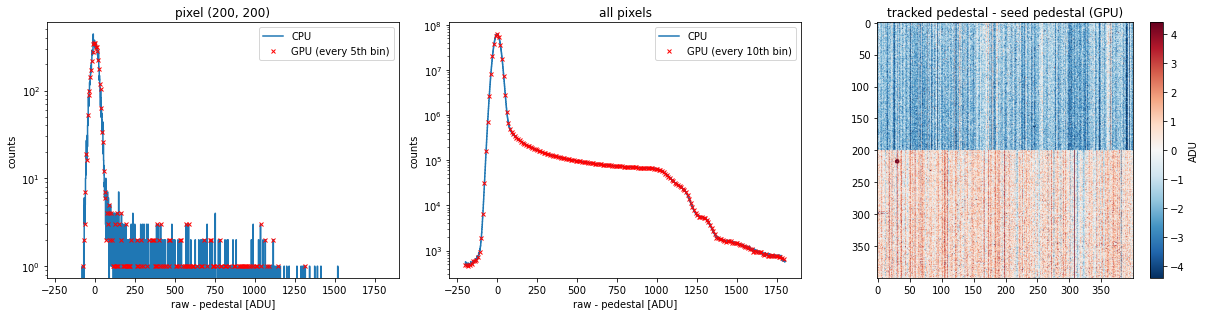

In [6]:
x = gpu.bin_centers()
row, col = rows // 2, cols // 2

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(17, 4.5), dpi=72)
ax1.step(x, values_cpu[row, col], where='mid', label='CPU')
ax1.plot(x, values_gpu[row, col], 'rx', ms=4, markevery=5, label='GPU (every 5th bin)')
ax1.set_yscale('log')
ax1.set(title=f'pixel ({row}, {col})', xlabel='raw - pedestal [ADU]', ylabel='counts')
ax1.legend()

ax2.step(x, values_cpu.sum(axis=(0, 1)), where='mid', label='CPU')
ax2.plot(x, values_gpu.sum(axis=(0, 1)), 'rx', ms=4, markevery=10, label='GPU (every 10th bin)')
ax2.set_yscale('log')
ax2.set(title='all pixels', xlabel='raw - pedestal [ADU]', ylabel='counts')
ax2.legend()

lim = np.percentile(np.abs(shift), 99)
im = ax3.imshow(shift, cmap='RdBu_r', vmin=-lim, vmax=lim)
fig.colorbar(im, ax=ax3, label='ADU')
ax3.set(title='tracked pedestal - seed pedestal (GPU)')
plt.tight_layout()